# Basic signals
Nesta atividades criaremos a nossa primeira **biblioteca de sinais digitais** com os sinais:

1. Delta: $\delta[n]$
2. Degrau: $u[n]$
3. Oscilação (periódico): $A \sin(\omega n + \phi)$
4. Exponencial
5. Aleatório (estocástico)


## Sinal delta, ou "impulso" - $\delta[n]$

<div style="text-align: center;">
    <img src="./figures/delta.png" alt="" width="500"/>
</div>


In [5]:
import numpy as np
import matplotlib.pyplot as plt
#import sys
#sys.path.append('/home/kuntur/Documents')
#from lib.myPlotLib import *

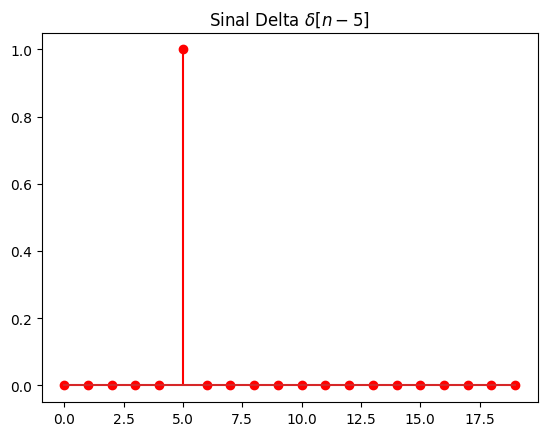

In [46]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Sinal delta (v1.0) - Usando numpy
N     = 20 # Número de amostras
xn    = np.zeros(N) # Inicializa com zeros
k     = 5 # Atraso (delay), ex: delta[n-5]
xn[k] = 1 # Define o impulso no índice k

# Vetor de amostras
n     = np.arange(N)

fig, ax = plt.subplots()
ax.stem(n, xn, 'r')
plt.title('Sinal Delta $\\delta[n-5]$')
plt.show()

## Sinal degrau - $u[n]$

<div style="text-align: center;">
    <img src="./figures/step.png" alt="" width="500"/>
</div>


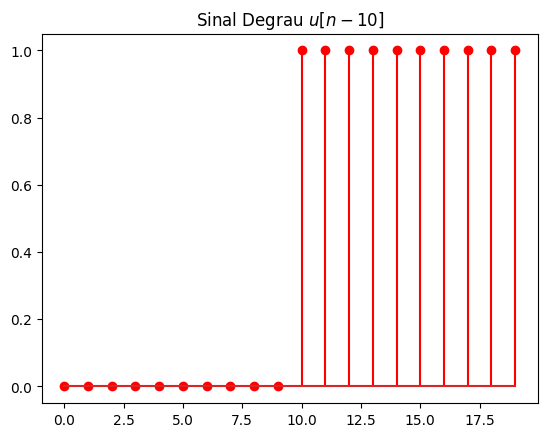

In [8]:
# 2. Degrau (v1.0) - Usando numpy
N = 20
k = 10
un = np.zeros(N)
un[k:] = 1 # Define 1 de k até o final

# Vetor de amostras
n  = np.arange(N)

fig, ax = plt.subplots()
ax.stem(n, un, 'r')
plt.title('Sinal Degrau $u[n-10]$')
plt.show()

## Sinal oscilatório, ou periódico - $A \sin(\omega n + \phi)$

<div style="text-align: center;">
    <img src="./figures/sine.png" alt="" width="500"/>
</div>


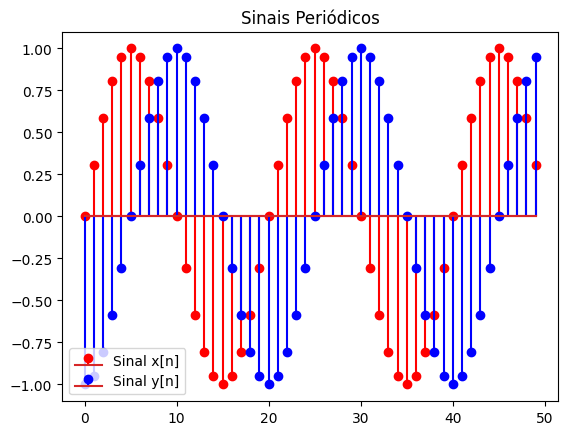

In [10]:
# 4. Sinal periodico
N  = 50 # numero de amostras
n  = np.arange(N) # vetor de amostras

A   = 1
P   = 20 # periodo do sinal
wo  = 2 * np.pi / P # frequencia digital
phi = 0 # fase

# Gerando os sinais senoidais
xn  = A * np.sin(wo * n + phi)
yn  = A * np.sin(wo * n + 3 * np.pi / 2)

# Plotagem
fig, ax = plt.subplots()
ax.stem(n, xn, 'ro', label='Sinal x[n]')
ax.stem(n, yn, 'bd', label='Sinal y[n]')
ax.legend()
plt.title('Sinais Periódicos')
# A função figureFormat não está definida, por isso comentamos:
# figureFormat(ax, fig, tight=True)
plt.show()

## Sinal exponencial - $|a|^{n} u[n]$

<div style="text-align: center;">
    <img src="./figures/exp.png" alt="" width="500"/>
</div>


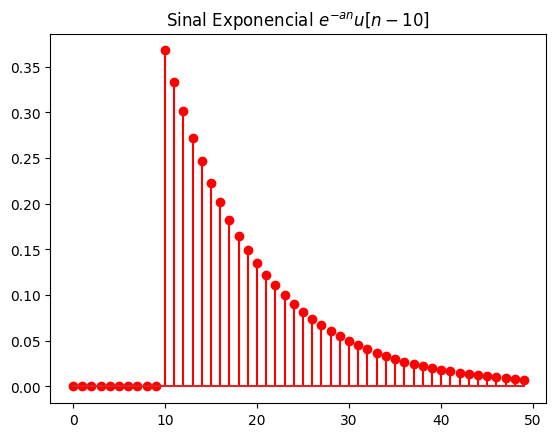

In [13]:
# 3. Exponencial
N = 50
n = np.arange(N)

# Criando um degrau compatível com o tamanho de n
un = np.zeros(N)
un[10:] = 1

a  = 0.1
yn = np.exp(-a * n) * un

fig, ax = plt.subplots()
ax.stem(n, yn, 'r')
plt.title('Sinal Exponencial $e^{-an} u[n-10]$')
# A função figureFormat não está definida, por isso comentamos:
# figureFormat(ax, fig, tight=True)
plt.show()

## Sinal aleatório - $x[n] = ?$

<div style="text-align: center;">
    <img src="./figures/random-Gaussian.png" alt="" width="500"/>
    <img src="./figures/random-uniform.png" alt="" width="500"/>
</div>


### Aleatório Gaussiano - $\mathcal{X} \sim \mathcal{N}(\mu, \sigma)$

<div style="text-align: center;">
    <img src="./figures/random-Gaussian-dist.png" alt="" width="500"/>
</div>


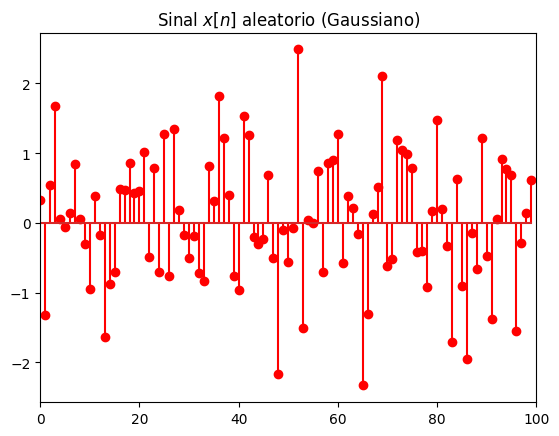

In [40]:
# 5. Sinal aleatorio (distribuicao Gaussiana)
N = 100
n = np.arange(N) # vetor de amostras

xn = np.random.randn(N) # Gaussiano (normal)

# Plot
fig, ax = plt.subplots(1)
ax.stem(n, xn, 'ro')
plt.xlim([0, 100])
ax.set_title(r'Sinal $x[n]$ aleatorio (Gaussiano)')
# figureFormat(ax, fig, tight=True)
plt.show()

Plote o **histograma** deste sinal.

**Dica:** Use `ax.hist`


In [41]:
# help(ax.hist)

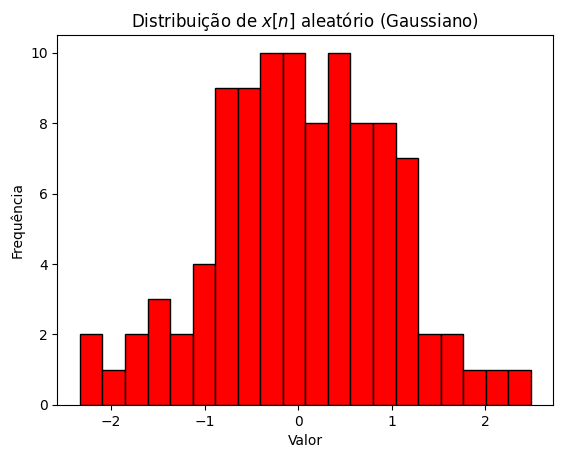

In [42]:
fig, ax = plt.subplots()
# Usamos o sinal 'xn' gerado na célula anterior e definimos 20 bins
ax.hist(xn, bins=20, color='r', edgecolor='black')
ax.set_title(r'Distribuição de $x[n]$ aleatório (Gaussiano)')
ax.set_xlabel('Valor')
ax.set_ylabel('Frequência')
# figureFormat(ax, fig, tight=True)
plt.show()

### Aleatório uniforme - $\mathcal{X} \sim \mathcal{U} \{a, b\}$

<div style="text-align: center;">
    <img src="./figures/random-uniform-dist.png" alt="" width="500"/>
</div>


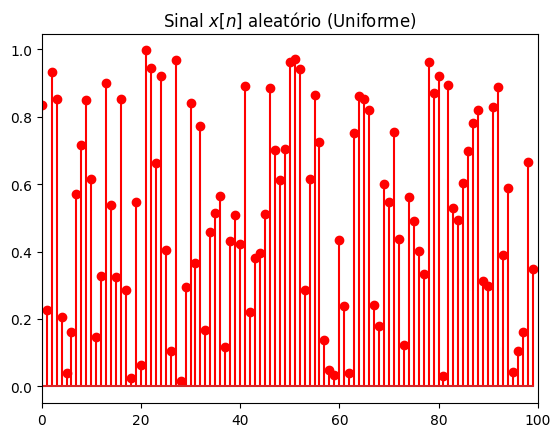

In [43]:
# 5. Sinal aleatorio (distribuicao uniforme)
N = 100
n = np.arange(N) # vetor de amostras

xn = np.random.rand(N) # uniforme (entre 0 e 1)

# Plot
fig, ax = plt.subplots(1)
ax.stem(n, xn, 'ro')
plt.xlim([0, 100])
ax.set_title(r'Sinal $x[n]$ aleatório (Uniforme)')
# figureFormat(ax, fig, tight=True)
plt.show()

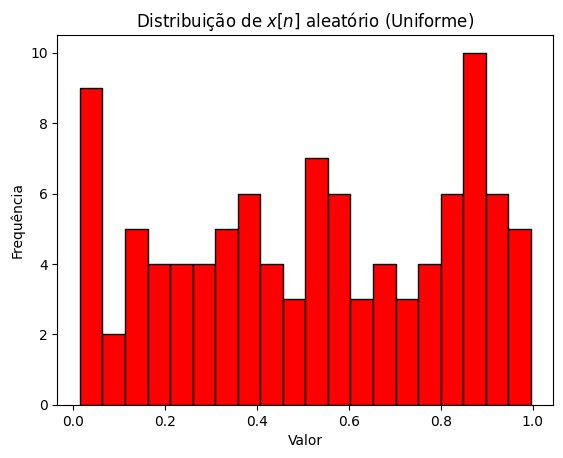

In [44]:
fig, ax = plt.subplots()
# Usamos o sinal 'xn' definido anteriormente e 20 bins para o histograma
ax.hist(xn, bins=20, color='r', edgecolor='black')
ax.set_title(r'Distribuição de $x[n]$ aleatório (Uniforme)')
ax.set_xlabel('Valor')
ax.set_ylabel('Frequência')
# figureFormat(ax, fig, tight=True) # Função não definida
plt.show()

## Minha biblioteca de sinais básicos

In [83]:
def SIGNALgenerate(N=100, signal='delta', params=None):
    n = np.arange(N)
    x = np.zeros(N)

    def get_val(key, default):
        if isinstance(params, dict):
            return params.get(key, default)
        return params if params is not None else default

    if signal == 'delta':
        k = int(get_val('k', 0))
        if 0 <= k < N: x[k] = 1

    elif signal == 'step':
        k = int(get_val('k', 0))
        x[k:] = 1

    elif signal == 'exp':
        a_val = float(get_val('a', 0.1))
        b_val = float(get_val('b', 1.0))
        x = b_val * np.exp(-a_val * n)

    elif signal == 'osc':
        # Adicionando Amplitude (A) e Fase (phi) para melhor visualização
        P = float(get_val('P', 20))
        A = float(get_val('A', 1.0))
        phi = float(get_val('phi', 0.0))
        wo = 2 * np.pi / P
        # Usar cos ajuda a ver o período começando do pico se phi=0
        x = A * np.cos(wo * n + phi)

    elif signal == 'random':
        mode = get_val('mode', 'gaussian')
        if mode == 'uniform' or params == 'uniform':
            x = np.random.rand(N)
        else:
            x = np.random.randn(N)

    return np.array(x)

In [54]:
def SIGNALdelay(x, k):
    """
    Atrasa um sinal em k amostras
    """
    result = np.zeros_like(x)
    if k < len(x):
        result[k:] = x[:len(x)-k]
    return result

In [25]:
def SIGNALplot2(x):
    fig, ax = plt.subplots()
    ax.stem(x, 'r')
    # figureFormat(ax, fig, tight=True)
    plt.show()


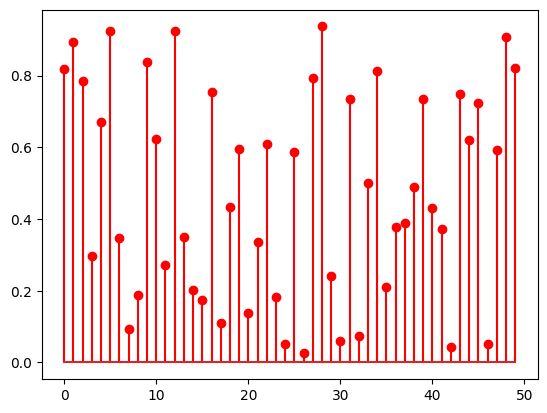

In [55]:
# Testando a biblioteca
# Agora que a lógica foi implementada, o gráfico deve aparecer
SIGNALplot2(SIGNALgenerate(50, 'random', 'uniform'))

### Testando o Sinal Exponencial via Biblioteca
Para o sinal exponencial, passamos o parâmetro `a` (decaimento). Quanto maior o `a`, mais rápido o sinal desce.

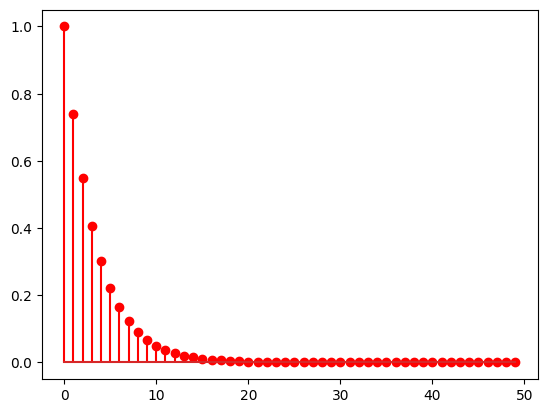

In [98]:
# Testando com P=8 e usando Cosseno (ajustado na lib)
# Agora o pico acontece exatamente nos múltiplos de 8 (0, 8, 16...)
dicio = {'a': 0.3, 'b': 1.0}

sinal = SIGNALgenerate(50, 'exp', dicio)

SIGNALplot2(sinal)